In [ ]:
# ============================================================
# 06_platform_insights.ipynb — 환경 설정 (config.py 자동 로드)
# ============================================================
import sys
import json
import matplotlib.patches as mpatches
from pathlib import Path

# 프로젝트 루트를 sys.path에 추가 (실행 위치 무관)
for _p in [Path.cwd(), Path.cwd().parent]:
    if (_p / 'config.py').exists():
        sys.path.insert(0, str(_p))
        break

from config import *  # 모든 상수·경로·KPI·시각화 설정·헬퍼 함수 일괄 적용
# ↑ KPI_REVPAR_ACTIVE_MEDIAN, KPI_DORMANT_RATIO, KPI_SUPERHOST_PREMIUM,
#   CLUSTER_COLORS, PROCESSED_DIR, REPORTS_DIR, load_features(), load_district_clustered() 포함

# ── 데이터 로드
try:
    dc = load_district_clustered()
    print(f"클러스터 데이터 로드: {dc.shape}")
except FileNotFoundError:
    dc = None
    print("district_clustered.csv 없음 — 05_platform_clustering.ipynb 먼저 실행")

df_ao = load_features(active_only=True)
print(f"Active+Oper: {len(df_ao):,}건")

# 💡 플랫폼 인사이트 — 자치구 전략 매트릭스

**목적:** K-Means 클러스터 결과를 기반으로 플랫폼 운영 전략을 수립합니다.

**인사이트 영역:**
1. TTM vs L90D RevPAR 트렌드
2. 규제 리스크 분석 (Non-Operating 비율)
3. 플랫폼 전략 매트릭스 (K-Means 클러스터 기반)

> **참고:** 인구 구조 × 상권 유형 통합 분석 및 핵심 발견사항 요약은 `07_district_population_analysis.ipynb` 3단계 이후에 포함되어 있습니다.

## 1️⃣ TTM vs L90D RevPAR 트렌드

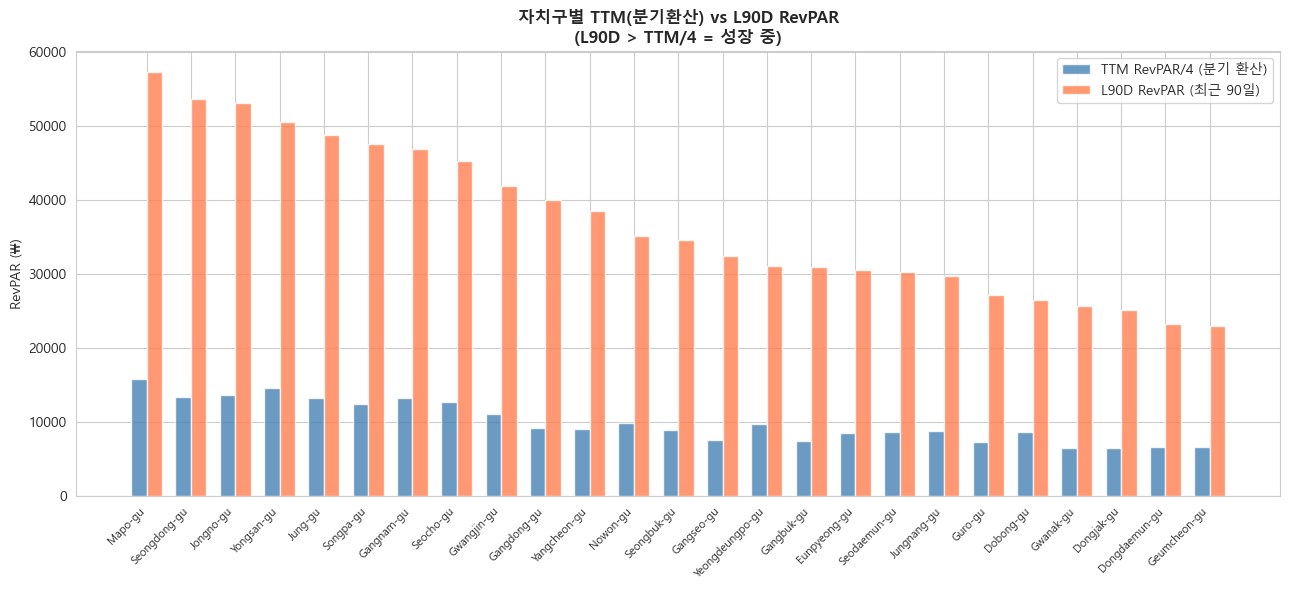

L90D > TTM/4 (성장): 25/25 자치구
성장 자치구: ['Mapo-gu', 'Seongdong-gu', 'Jongno-gu', 'Yongsan-gu', 'Jung-gu', 'Songpa-gu', 'Gangnam-gu', 'Seocho-gu', 'Gwangjin-gu', 'Gangdong-gu', 'Yangcheon-gu', 'Nowon-gu', 'Seongbuk-gu', 'Gangseo-gu', 'Yeongdeungpo-gu', 'Gangbuk-gu', 'Eunpyeong-gu', 'Seodaemun-gu', 'Jungnang-gu', 'Guro-gu', 'Dobong-gu', 'Gwanak-gu', 'Dongjak-gu', 'Dongdaemun-gu', 'Geumcheon-gu']


In [2]:
trend = df_ao.groupby("district").agg(ttm_med=("ttm_revpar","median"), l90d_med=("l90d_revpar","median"), ao_count=("ttm_revpar","count")).reset_index()
trend["ttm_quarterly"] = trend["ttm_med"]/4
trend["growth"] = trend["l90d_med"] > trend["ttm_quarterly"]
trend = trend.sort_values("l90d_med", ascending=False)

fig, ax = plt.subplots(figsize=(13, 6))
x = range(len(trend)); w = 0.35
ax.bar([i-w/2 for i in x], trend["ttm_quarterly"], w, label="TTM RevPAR/4 (분기 환산)", color="steelblue", alpha=0.8)
ax.bar([i+w/2 for i in x], trend["l90d_med"], w, label="L90D RevPAR (최근 90일)", color="coral", alpha=0.8)
ax.set_title("자치구별 TTM(분기환산) vs L90D RevPAR\n(L90D > TTM/4 = 성장 중)", fontsize=12, fontweight="bold")
ax.set_ylabel("RevPAR (₩)"); ax.set_xticks(x); ax.set_xticklabels(trend["district"], rotation=45, ha="right", fontsize=8); ax.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR/"fig_06_ttm_vs_l90d.png", dpi=100, bbox_inches="tight"); plt.show()
print(f"L90D > TTM/4 (성장): {trend['growth'].sum()}/{len(trend)} 자치구")
print(f"성장 자치구: {trend[trend['growth']]['district'].tolist()}")

## 2️⃣ 규제 리스크 분석 (Non-Operating 비율)

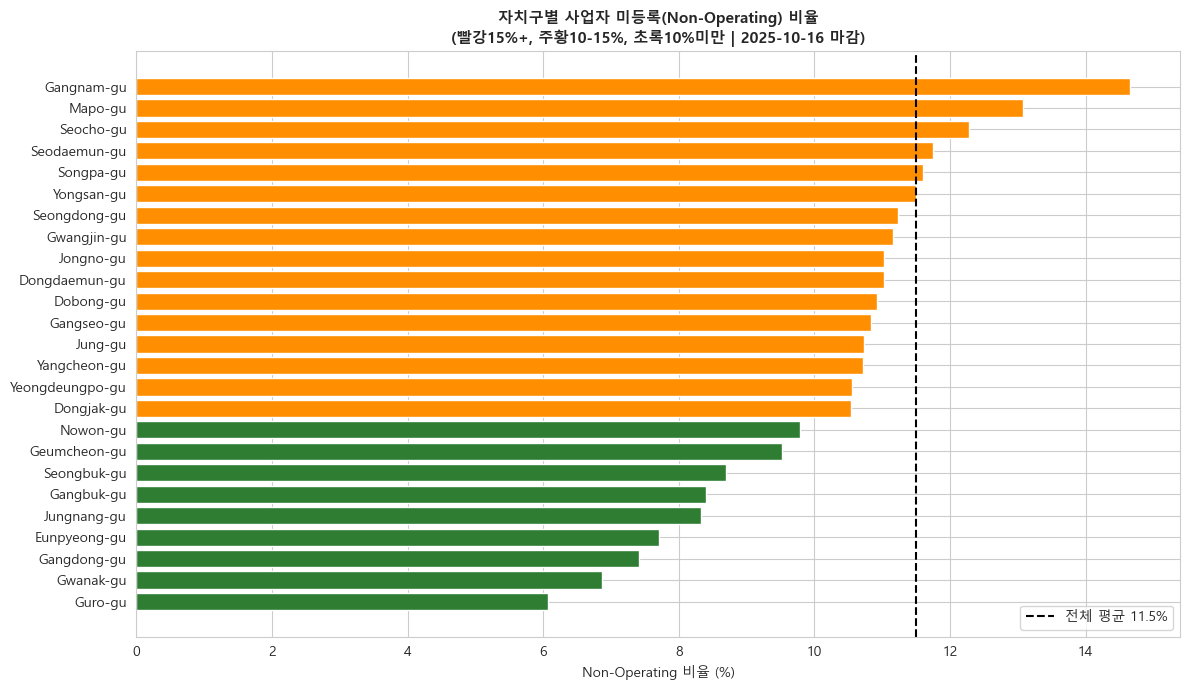

⚠️ 규제 고위험 자치구 (15%+): []


In [3]:
df_all = pd.read_csv("../data/raw/seoul_airbnb_cleaned.csv")
dreg = df_all.groupby("district").agg(total=("ttm_revpar","count"), non_op=("operation_status", lambda x: (x=="Non_Operating").sum())).reset_index()
dreg["non_op_rate"] = dreg["non_op"]/dreg["total"]
dreg_sorted = dreg.sort_values("non_op_rate", ascending=True)
colors_reg = ["#C62828" if v>0.15 else "#FF8F00" if v>0.10 else "#2E7D32" for v in dreg_sorted["non_op_rate"]]
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(dreg_sorted["district"], dreg_sorted["non_op_rate"]*100, color=colors_reg)
ax.axvline(11.5, color="black", linestyle="--", linewidth=1.5, label="전체 평균 11.5%")
ax.set_title("자치구별 사업자 미등록(Non-Operating) 비율\n(빨강15%+, 주황10-15%, 초록10%미만 | 2025-10-16 마감)", fontsize=11, fontweight="bold")
ax.set_xlabel("Non-Operating 비율 (%)"); ax.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR/"fig_06_regulatory_risk.png", dpi=100, bbox_inches="tight"); plt.show()
high_risk = dreg[dreg["non_op_rate"]>0.15].sort_values("non_op_rate", ascending=False)
print(f"⚠️ 규제 고위험 자치구 (15%+): {high_risk['district'].tolist()}")

## 3️⃣ 플랫폼 전략 매트릭스

In [4]:
strategy_map = {
    "프리미엄 관광거점": {"전략":"고급화 유지","액션":["프리미엄 숙소 지원 강화","슈퍼호스트 비율 유지","가격 인상 가이드 제공"],"우선순위":"⭐⭐⭐"},
    "성장형 주거상권": {"전략":"적극 육성","액션":["슈퍼호스트 전환 지원","즉시예약 활성화 캠페인","Dormant 재활성화"],"우선순위":"⭐⭐⭐"},
    "중가 균형시장": {"전략":"안정적 성장","액션":["품질 향상 지원","사진 업로드 가이드","평점 개선 인센티브"],"우선순위":"⭐⭐"},
    "가격민감 외곽형": {"전략":"효율화","액션":["규제 준수 지원","Dormant 정리 권고","비수기 프로모션"],"우선순위":"⭐"}
}
print("="*70)
print("📋 자치구별 플랫폼 운영 전략 매트릭스")
print("="*70)
for cname, st in strategy_map.items():
    members = dc[dc["cluster_name"]==cname]["district"].tolist() if dc is not None else []
    revpar = dc[dc["cluster_name"]==cname]["median_revpar_ao"].median() if dc is not None else 0
    print(f"\n{st['우선순위']} [{cname}]")
    if members: print(f"  자치구: {', '.join(members)}")
    if revpar > 0: print(f"  RevPAR 중위값: ₩{revpar:,.0f}")
    print(f"  전략: {st['전략']}")
    for a in st["액션"]: print(f"    - {a}")
print("="*70)

📋 자치구별 플랫폼 운영 전략 매트릭스

⭐⭐⭐ [프리미엄 관광거점]
  자치구: Mapo-gu
  RevPAR 중위값: ₩63,366
  전략: 고급화 유지
    - 프리미엄 숙소 지원 강화
    - 슈퍼호스트 비율 유지
    - 가격 인상 가이드 제공

⭐⭐⭐ [성장형 주거상권]
  자치구: Gangnam-gu, Jongno-gu, Jung-gu, Seocho-gu, Yongsan-gu
  RevPAR 중위값: ₩53,052
  전략: 적극 육성
    - 슈퍼호스트 전환 지원
    - 즉시예약 활성화 캠페인
    - Dormant 재활성화

⭐⭐ [중가 균형시장]
  자치구: Dobong-gu, Eunpyeong-gu, Gangbuk-gu, Gangdong-gu, Gangseo-gu, Gwangjin-gu, Jungnang-gu, Nowon-gu, Seongbuk-gu, Seongdong-gu, Songpa-gu, Yangcheon-gu, Yeongdeungpo-gu
  RevPAR 중위값: ₩35,881
  전략: 안정적 성장
    - 품질 향상 지원
    - 사진 업로드 가이드
    - 평점 개선 인센티브

⭐ [가격민감 외곽형]
  자치구: Dongdaemun-gu, Dongjak-gu, Geumcheon-gu, Guro-gu, Gwanak-gu, Seodaemun-gu
  RevPAR 중위값: ₩26,413
  전략: 효율화
    - 규제 준수 지원
    - Dormant 정리 권고
    - 비수기 프로모션
